# 🌍 GREEN MIRAGE 2.0

## Global Energy Transition Intelligence System

### From Energy Analysis to Machine Learning

**Research Question:**

Are countries genuinely transitioning away from fossil fuels,
or are renewable energy sources simply expanding alongside
growing energy demand?

### Research Objectives

1. Analyze global renewable energy and fossil-fuel trends.
2. Compare five selected countries.
3. Engineer meaningful energy-transition indicators.
4. Discover country patterns using Machine Learning.
5. Predict next-year renewable energy shares.
6. Evaluate and interpret model performance.

### Technologies

Python | Pandas | NumPy | Matplotlib | Seaborn |
Scikit-learn | Google Colab

### Dataset

Our World in Data – Global Energy Dataset

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [44]:
DATA_URL = (
    "https://catalog.ourworldindata.org/garden/energy/"
    "2026-09-10/owid_energy/owid_energy.csv"
)

COUNTRIES = [
    "India",
    "China",
    "Germany",
    "Brazil",
    "United States"
]

START_YEAR = 2000
END_YEAR = 2025

VISUALS_DIR = Path("green_mirage_visualizations")
OUTPUT_DIR = Path("green_mirage_outputs")

VISUALS_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project configuration completed.")
print("Countries:", COUNTRIES)
print("Analysis period:", START_YEAR, "-", END_YEAR)

Project configuration completed.
Countries: ['India', 'China', 'Germany', 'Brazil', 'United States']
Analysis period: 2000 - 2025


In [45]:
df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully!")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 19494
Columns: 130


,country,year,iso_code,population,gdp,bioenergy_electricity_per_capita_kwh,bioenergy_electricity_share_pct,bioenergy_electricity_twh,biofuels_energy_annual_change_pct,biofuels_energy_annual_change_twh,...,total_energy_per_gdp_kwh_per_dollar,total_energy_twh,wind_electricity_per_capita_kwh,wind_electricity_share_pct,wind_electricity_twh,wind_energy_annual_change_pct,wind_energy_annual_change_twh,wind_energy_per_capita_kwh,wind_energy_share_pct,wind_energy_twh
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,1.549794,5.87,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,1.594707,6.46,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,1.528198,6.62,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,1.623391,7.44,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,1.689455,8.39,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [46]:
print("DATASET INFORMATION")
print("--------------------")

df.info()

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nMISSING VALUES:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T.head(20))

DATASET INFORMATION
--------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19494 entries, 0 to 19493
Columns: 130 entries, country to wind_energy_twh
dtypes: float64(127), int64(1), object(2)
memory usage: 19.3+ MB

COLUMN NAMES:
['country', 'year', 'iso_code', 'population', 'gdp', 'bioenergy_electricity_per_capita_kwh', 'bioenergy_electricity_share_pct', 'bioenergy_electricity_twh', 'biofuels_energy_annual_change_pct', 'biofuels_energy_annual_change_twh', 'biofuels_energy_per_capita_kwh', 'biofuels_energy_share_pct', 'biofuels_energy_twh', 'coal_electricity_per_capita_kwh', 'coal_electricity_share_pct', 'coal_electricity_twh', 'coal_energy_annual_change_pct', 'coal_energy_annual_change_twh', 'coal_energy_per_capita_kwh', 'coal_energy_share_pct', 'coal_energy_twh', 'coal_production_annual_change_pct', 'coal_production_annual_change_twh', 'coal_production_per_capita_kwh', 'coal_production_twh', 'electricity_carbon_intensity_gco2eq_per_kwh', 'electricity_demand_per_capita

,0
biofuels_energy_annual_change_pct,17603
solar_energy_annual_change_pct,17185
nuclear_energy_annual_change_pct,16979
wind_energy_annual_change_pct,16917
biofuels_energy_per_capita_kwh,16820
biofuels_energy_annual_change_twh,16519
biofuels_energy_twh,16425
biofuels_energy_share_pct,16425
other_renewables_including_bioenergy_energy_annual_change_pct,15921
electricity_share_of_total_energy_pct,15472



STATISTICAL SUMMARY:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,19494,260,United Kingdom,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,19494.0,NaN,NaN,NaN,1974.831128,40.185631,1700.0,1948.0,1986.0,2006.0,2025.0
iso_code,17480,220,GBR,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population,18319.0,NaN,NaN,NaN,94202422.148043,472877230.370045,1776.0,1511983.0,6613368.0,22336436.5,8231613067.0
gdp,11834.0,NaN,NaN,NaN,425279710395.934998,3499917225101.624512,164206000.0,14509937056.25,44583533187.5,184587238878.25,130112562171125.0
bioenergy_electricity_per_capita_kwh,6115.0,NaN,NaN,NaN,69.369327,198.623087,0.0,0.0,0.786575,42.75795,2450.790527
bioenergy_electricity_share_pct,6411.0,NaN,NaN,NaN,1.934032,5.316626,0.0,0.0,0.146628,1.56456,77.586205
bioenergy_electricity_twh,6437.0,NaN,NaN,NaN,12.612676,53.042531,0.0,0.0,0.02,0.89,710.409973
biofuels_energy_annual_change_pct,1891.0,NaN,NaN,NaN,50.089041,366.698153,-100.0,-0.79266,7.671839,26.213134,11165.0
biofuels_energy_annual_change_twh,2975.0,NaN,NaN,NaN,2.66916,10.846824,-59.753052,0.0,0.0,0.690556,144.299042


In [47]:
# Find the first available column from a list of alternatives

def find_column(candidates, required=True):
    for col in candidates:
        if col in df.columns:
            return col

    if required:
        raise ValueError(
            f"Required column not found. Tried: {candidates}"
        )

    return None


column_map = {
    "country": find_column(["country", "entity"]),
    "year": find_column(["year"]),

    "total_energy_twh": find_column([
        "total_energy_twh",
        "primary_energy_consumption",
        "primary_energy_consumption_twh"
    ], required=False),

    "renewables_energy_twh": find_column([
        "renewables_energy_twh",
        "renewables_consumption",
        "renewables_consumption_twh"
    ], required=False),

    "fossil_fuels_energy_twh": find_column([
        "fossil_fuels_energy_twh",
        "fossil_fuel_consumption",
        "fossil_fuel_consumption_twh"
    ], required=False),

    "renewables_energy_share_pct": find_column([
        "renewables_energy_share_pct",
        "renewables_share_energy"
    ], required=False),

    "fossil_fuels_energy_share_pct": find_column([
        "fossil_fuels_energy_share_pct",
        "fossil_share_energy"
    ], required=False),

    "population": find_column([
        "population"
    ], required=False),

    "gdp": find_column([
        "gdp"
    ], required=False)
}

print("COLUMN MAPPING")
display(pd.DataFrame(
    [(key, value) for key, value in column_map.items()],
    columns=["Standard Name", "Dataset Column"]
))

COLUMN MAPPING


,Standard Name,Dataset Column
0,country,country
1,year,year
2,total_energy_twh,total_energy_twh
3,renewables_energy_twh,renewables_energy_twh
4,fossil_fuels_energy_twh,fossil_fuels_energy_twh
5,renewables_energy_share_pct,renewables_energy_share_pct
6,fossil_fuels_energy_share_pct,fossil_fuels_energy_share_pct
7,population,population
8,gdp,gdp


In [48]:
rename_map = {
    original: standard
    for standard, original in column_map.items()
    if original is not None
}

energy = df[list(rename_map.keys())].rename(
    columns={v: k for k, v in rename_map.items()}
).copy()

energy["year"] = pd.to_numeric(
    energy["year"], errors="coerce"
)

energy = energy.dropna(subset=["country", "year"])

energy["year"] = energy["year"].astype(int)

numeric_columns = [
    col for col in energy.columns
    if col not in ["country", "year"]
]

for col in numeric_columns:
    energy[col] = pd.to_numeric(
        energy[col], errors="coerce"
    )

energy = energy[
    energy["year"].between(START_YEAR, END_YEAR)
].copy()

energy = energy.drop_duplicates(
    subset=["country", "year"]
)

energy = energy.sort_values(
    ["country", "year"]
).reset_index(drop=True)

print("Clean dataset created!")
print("Rows:", len(energy))
print("Countries:", energy["country"].nunique())

display(energy.head())

Clean dataset created!
Rows: 6484
Countries: 255


,country,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct,population,gdp
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [49]:
required_indicators = [
    "renewables_energy_twh",
    "fossil_fuels_energy_twh",
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

available_indicators = [
    col for col in required_indicators
    if col in energy.columns
]

missing_indicators = [
    col for col in required_indicators
    if col not in energy.columns
]

print("AVAILABLE INDICATORS:")
print(available_indicators)

print("\nMISSING INDICATORS:")
print(missing_indicators)

if "renewables_energy_share_pct" not in energy.columns:
    raise ValueError(
        "Renewable energy share is required for this project."
    )

if "fossil_fuels_energy_share_pct" not in energy.columns:
    raise ValueError(
        "Fossil fuel energy share is required for this project."
    )

AVAILABLE INDICATORS:
['renewables_energy_twh', 'fossil_fuels_energy_twh', 'renewables_energy_share_pct', 'fossil_fuels_energy_share_pct']

MISSING INDICATORS:
[]


In [50]:
five_country_data = energy[
    energy["country"].isin(COUNTRIES)
].copy()

print("FIVE-COUNTRY RESEARCH DATA")
print("--------------------------")

display(
    five_country_data.groupby("country")
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("year", "count")
    )
)

FIVE-COUNTRY RESEARCH DATA
--------------------------


,first_year,last_year,observations
country,,,
Brazil,2000,2025,26
China,2000,2025,26
Germany,2000,2025,26
India,2000,2025,26
United States,2000,2025,26


In [51]:
missing_report = (
    five_country_data.isnull()
    .sum()
    .reset_index()
)

missing_report.columns = [
    "Indicator",
    "Missing Values"
]

missing_report["Missing Percentage"] = (
    missing_report["Missing Values"]
    / len(five_country_data)
    * 100
)

display(
    missing_report.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Indicator,Missing Values,Missing Percentage
8,gdp,15,11.538462
0,country,0,0.000000
1,year,0,0.000000
3,renewables_energy_twh,0,0.000000
2,total_energy_twh,0,0.000000
4,fossil_fuels_energy_twh,0,0.000000
5,renewables_energy_share_pct,0,0.000000
6,fossil_fuels_energy_share_pct,0,0.000000
7,population,0,0.000000


In [52]:
feature_data = energy.copy()

# Renewable energy share relative to fossil fuel share
feature_data["renewable_fossil_share_gap"] = (
    feature_data["renewables_energy_share_pct"]
    - feature_data["fossil_fuels_energy_share_pct"]
)

# Renewable energy as a proportion of renewable + fossil energy
feature_data["renewable_to_fossil_ratio"] = (
    feature_data["renewables_energy_share_pct"]
    / feature_data["fossil_fuels_energy_share_pct"].replace(0, np.nan)
)

# Energy consumption per capita
if "total_energy_twh" in feature_data.columns and "population" in feature_data.columns:
    feature_data["energy_per_capita_kwh"] = (
        feature_data["total_energy_twh"] * 1e9
        / feature_data["population"].replace(0, np.nan)
    )

# GDP per capita
if "gdp" in feature_data.columns and "population" in feature_data.columns:
    feature_data["gdp_per_capita"] = (
        feature_data["gdp"]
        / feature_data["population"].replace(0, np.nan)
    )

# Year-on-year renewable energy growth
if "renewables_energy_twh" in feature_data.columns:
    feature_data["renewable_growth_pct"] = (
        feature_data.groupby("country")["renewables_energy_twh"]
        .pct_change(fill_method=None) * 100
    )

# Year-on-year fossil-fuel energy growth
if "fossil_fuels_energy_twh" in feature_data.columns:
    feature_data["fossil_growth_pct"] = (
        feature_data.groupby("country")["fossil_fuels_energy_twh"]
        .pct_change(fill_method=None) * 100
    )

feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

print("Feature engineering completed!")

display(feature_data.head())

Feature engineering completed!


,country,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct,population,gdp,renewable_fossil_share_gap,renewable_to_fossil_ratio,energy_per_capita_kwh,gdp_per_capita,renewable_growth_pct,fossil_growth_pct
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [53]:
case_study = feature_data[
    feature_data["country"].isin(COUNTRIES)
].copy()

comparison_columns = [
    col for col in [
        "country",
        "year",
        "total_energy_twh",
        "renewables_energy_twh",
        "fossil_fuels_energy_twh",
        "renewables_energy_share_pct",
        "fossil_fuels_energy_share_pct",
        "renewable_fossil_share_gap",
        "energy_per_capita_kwh",
        "gdp_per_capita"
    ]
    if col in case_study.columns
]

display(
    case_study[comparison_columns].head(15)
)

,country,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct,renewable_fossil_share_gap,energy_per_capita_kwh,gdp_per_capita
845,Brazil,2000,1768.432983,403.299561,1346.812256,22.805475,76.158508,-53.353033,10162.340438,9997.386791
846,Brazil,2001,1786.451782,365.641052,1377.541016,20.467445,77.110451,-56.643005,10132.952992,10127.628151
847,Brazil,2002,1803.965820,393.556305,1368.482178,21.816174,75.859650,-54.043476,10106.053786,10429.725357
848,Brazil,2003,1806.880737,414.576447,1351.825439,22.944319,74.815422,-51.871103,10003.620018,10546.475238
849,Brazil,2004,1900.681152,439.734009,1425.762329,23.135601,75.013229,-51.877628,10404.705921,11158.868616
850,Brazil,2005,1940.643921,464.081421,1446.698853,23.913786,74.547363,-50.633577,10507.682468,11528.704442
851,Brazil,2006,1999.178711,475.909851,1481.589722,23.805267,74.109924,-50.304657,10710.664445,12005.186793
852,Brazil,2007,2126.763916,537.496094,1551.844116,25.272955,72.967392,-47.694437,11279.437015,12758.405817
853,Brazil,2008,2266.752686,578.790100,1645.633789,25.533890,72.598732,-47.064842,11907.258869,13446.861411
854,Brazil,2009,2223.208252,622.318054,1561.626709,27.991892,70.242035,-42.250143,11574.389515,13481.721171


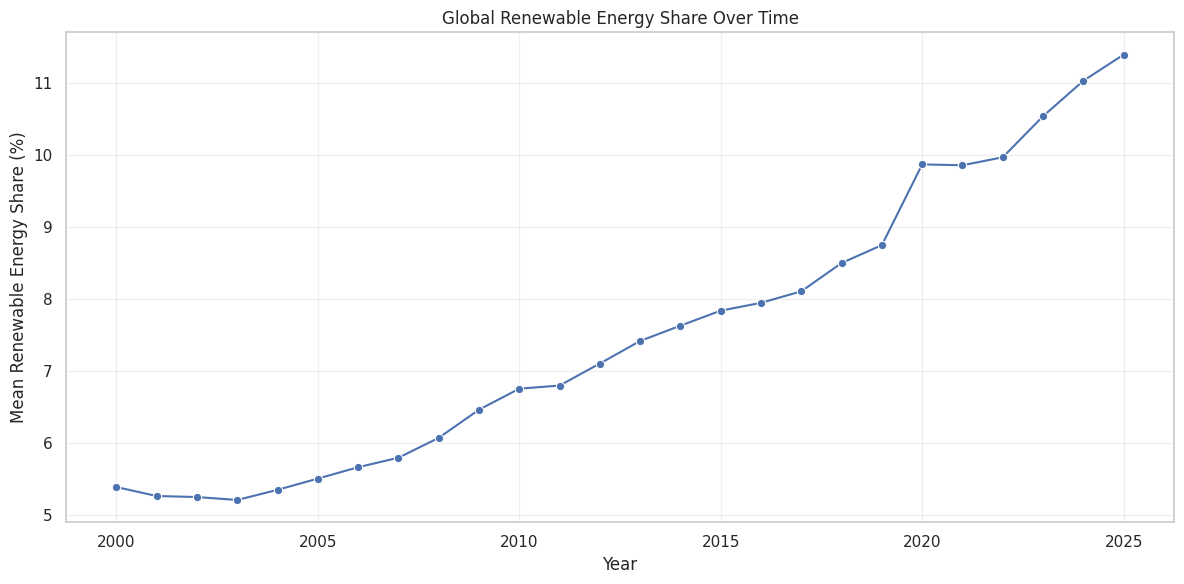

In [54]:
global_trends = (
    feature_data.groupby("year")
    ["renewables_energy_share_pct"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=global_trends,
    x="year",
    y="renewables_energy_share_pct",
    marker="o"
)

plt.title("Global Renewable Energy Share Over Time")
plt.xlabel("Year")
plt.ylabel("Mean Renewable Energy Share (%)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "06_global_renewable_trends.png",
    dpi=300
)

plt.show()

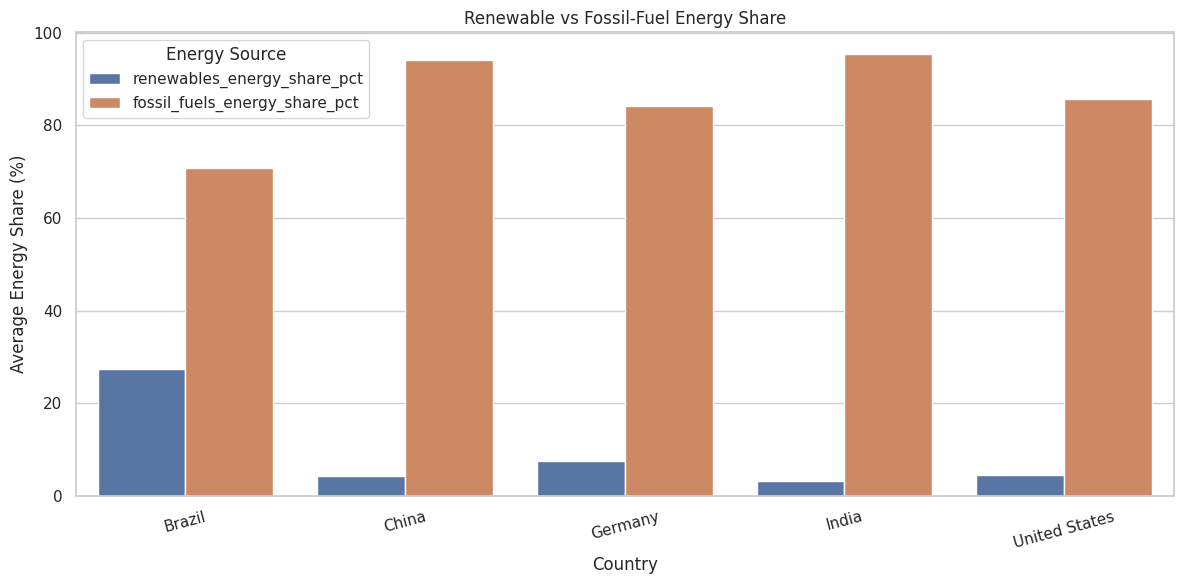

In [55]:
share_comparison = (
    case_study.groupby("country")[
        [
            "renewables_energy_share_pct",
            "fossil_fuels_energy_share_pct"
        ]
    ]
    .mean()
    .reset_index()
)

share_comparison = share_comparison.melt(
    id_vars="country",
    var_name="Energy Source",
    value_name="Average Share (%)"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=share_comparison,
    x="country",
    y="Average Share (%)",
    hue="Energy Source"
)

plt.title("Renewable vs Fossil-Fuel Energy Share")
plt.xlabel("Country")
plt.ylabel("Average Energy Share (%)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "07_energy_share_comparison.png",
    dpi=300
)

plt.show()

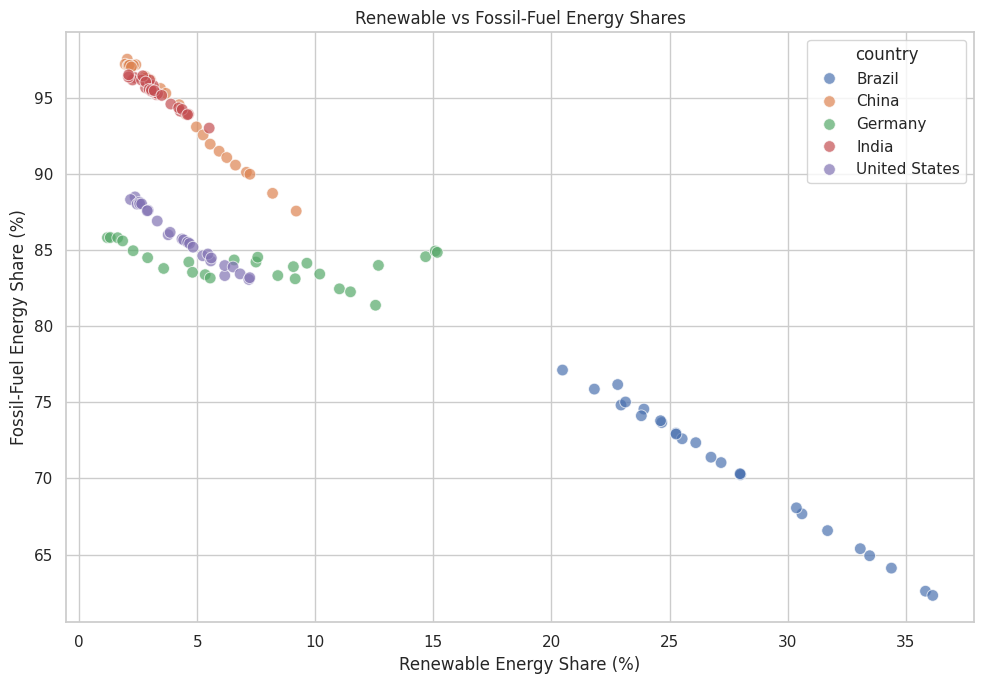

In [56]:
scatter_data = case_study.dropna(
    subset=[
        "renewables_energy_share_pct",
        "fossil_fuels_energy_share_pct"
    ]
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=scatter_data,
    x="renewables_energy_share_pct",
    y="fossil_fuels_energy_share_pct",
    hue="country",
    alpha=0.7,
    s=70
)

plt.title("Renewable vs Fossil-Fuel Energy Shares")
plt.xlabel("Renewable Energy Share (%)")
plt.ylabel("Fossil-Fuel Energy Share (%)")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "08_energy_transition_scatter.png",
    dpi=300
)

plt.show()

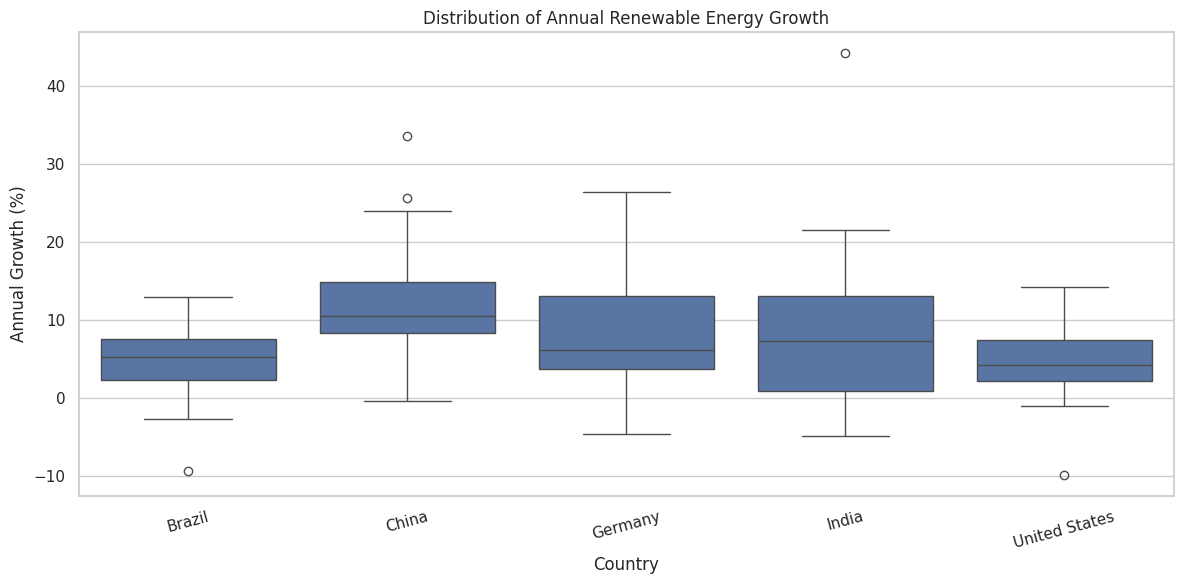

In [57]:
growth_data = case_study.dropna(
    subset=["renewable_growth_pct"]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=growth_data,
    x="country",
    y="renewable_growth_pct"
)

plt.title("Distribution of Annual Renewable Energy Growth")
plt.xlabel("Country")
plt.ylabel("Annual Growth (%)")

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "09_renewable_growth_distribution.png",
    dpi=300
)

plt.show()

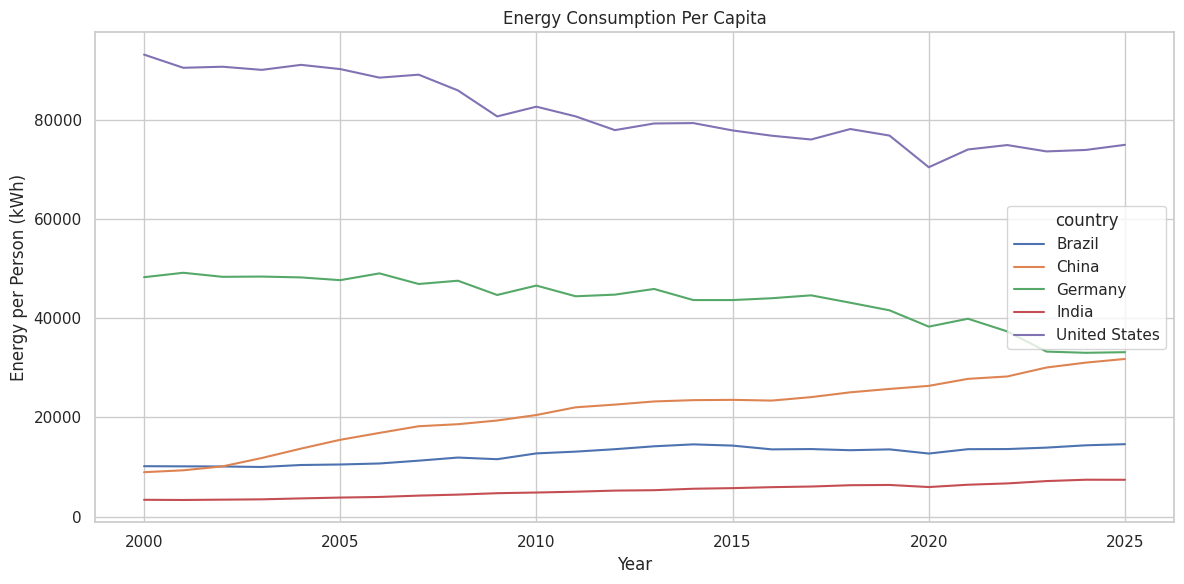

In [58]:
if "energy_per_capita_kwh" in case_study.columns:

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=case_study,
        x="year",
        y="energy_per_capita_kwh",
        hue="country"
    )

    plt.title("Energy Consumption Per Capita")
    plt.xlabel("Year")
    plt.ylabel("Energy per Person (kWh)")

    plt.tight_layout()

    plt.savefig(
        VISUALS_DIR / "10_energy_per_capita.png",
        dpi=300
    )

    plt.show()

else:
    print("Population or total energy data unavailable.")

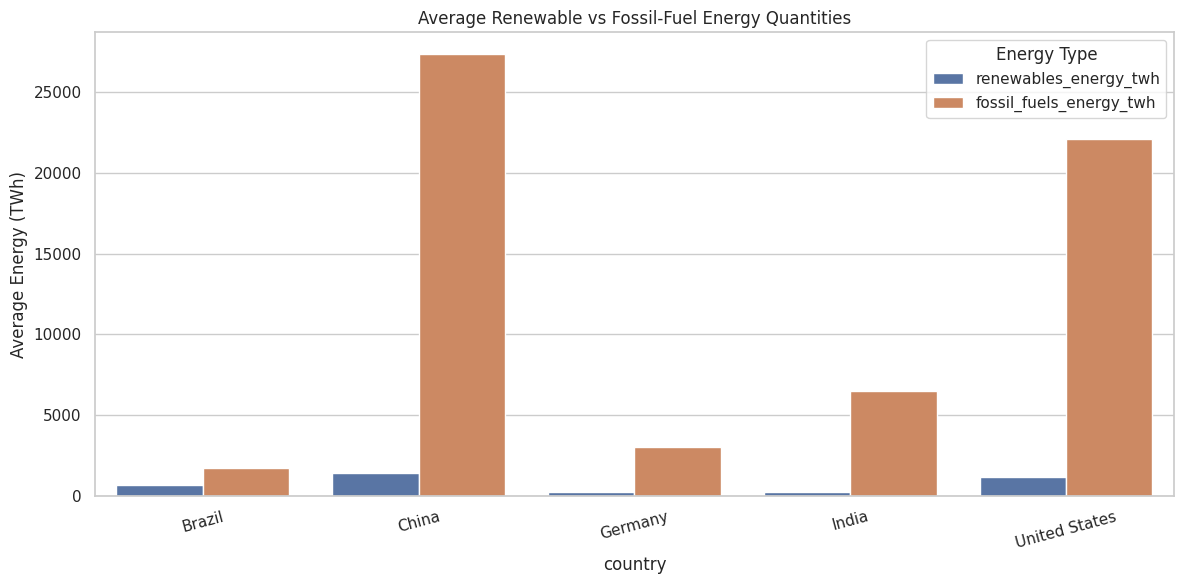

In [59]:
if all(
    col in case_study.columns
    for col in [
        "renewables_energy_twh",
        "fossil_fuels_energy_twh"
    ]
):

    quantity_comparison = (
        case_study.groupby("country")[
            [
                "renewables_energy_twh",
                "fossil_fuels_energy_twh"
            ]
        ].mean().reset_index()
    )

    quantity_comparison = quantity_comparison.melt(
        id_vars="country",
        var_name="Energy Type",
        value_name="Average Energy (TWh)"
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=quantity_comparison,
        x="country",
        y="Average Energy (TWh)",
        hue="Energy Type"
    )

    plt.title("Average Renewable vs Fossil-Fuel Energy Quantities")
    plt.xticks(rotation=15)
    plt.tight_layout()

    plt.savefig(
        VISUALS_DIR / "11_energy_quantity_comparison.png",
        dpi=300
    )

    plt.show()

else:
    print("Energy quantity columns unavailable.")

In [60]:
research_summary = (
    case_study.groupby("country")
    .agg(
        average_renewable_share=(
            "renewables_energy_share_pct", "mean"
        ),
        average_fossil_share=(
            "fossil_fuels_energy_share_pct", "mean"
        ),
        observations=("year", "count")
    )
    .reset_index()
)

research_summary["share_gap"] = (
    research_summary["average_renewable_share"]
    - research_summary["average_fossil_share"]
)

research_summary = research_summary.sort_values(
    "average_renewable_share",
    ascending=False
)

display(research_summary.round(2))

,country,average_renewable_share,average_fossil_share,observations,share_gap
0,Brazil,27.46,70.80,26,-43.34
2,Germany,7.53,84.06,26,-76.53
4,United States,4.47,85.75,26,-81.28
1,China,4.26,94.18,26,-89.92
3,India,3.31,95.31,26,-92.00


In [61]:
cluster_features = [
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct",
    "renewable_fossil_share_gap"
]

if "energy_per_capita_kwh" in feature_data.columns:
    cluster_features.append("energy_per_capita_kwh")

if "renewable_growth_pct" in feature_data.columns:
    cluster_features.append("renewable_growth_pct")

if "gdp_per_capita" in feature_data.columns:
    cluster_features.append("gdp_per_capita")

cluster_source = feature_data[
    feature_data["year"].between(2015, 2025)
].copy()

cluster_table = (
    cluster_source.groupby("country")[cluster_features]
    .mean()
)

# Remove countries with insufficient observations
country_counts = (
    cluster_source.groupby("country")["year"].count()
)

cluster_table = cluster_table[
    country_counts.reindex(cluster_table.index).fillna(0) >= 5
]

# Remove indicators with no usable values
cluster_table = cluster_table.dropna(
    axis=1,
    how="all"
)

# Remove indicators with no variation
cluster_table = cluster_table.loc[
    :,
    cluster_table.nunique(dropna=True) > 1
]

cluster_table = cluster_table.dropna(
    axis=0,
    how="all"
)

print("Countries available for clustering:", len(cluster_table))
print("Features used:", cluster_table.columns.tolist())

display(cluster_table.head())

Countries available for clustering: 236
Features used: ['renewables_energy_share_pct', 'fossil_fuels_energy_share_pct', 'renewable_fossil_share_gap', 'energy_per_capita_kwh', 'renewable_growth_pct', 'gdp_per_capita']


,renewables_energy_share_pct,fossil_fuels_energy_share_pct,renewable_fossil_share_gap,energy_per_capita_kwh,renewable_growth_pct,gdp_per_capita
country,,,,,,
Afghanistan,NaN,NaN,NaN,1065.535944,NaN,1727.646869
Africa,4.553097,94.779547,-90.226450,3929.686857,6.608672,NaN
Africa (EI),4.553097,94.779547,-90.226450,NaN,6.608672,NaN
Albania,NaN,NaN,NaN,8922.319264,NaN,11293.004313
Algeria,0.089219,99.910780,-99.821562,15779.326200,12.011449,13458.633415


In [62]:
cluster_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_cluster = cluster_pipeline.fit_transform(
    cluster_table
)

print("Clustering features standardized!")
print("Shape:", X_cluster.shape)

Clustering features standardized!
Shape: (236, 6)


,Clusters,Silhouette Score
0,2,0.663671
1,3,0.714511
2,4,0.502961
3,5,0.512670
4,6,0.545147
5,7,0.509921
6,8,0.490570


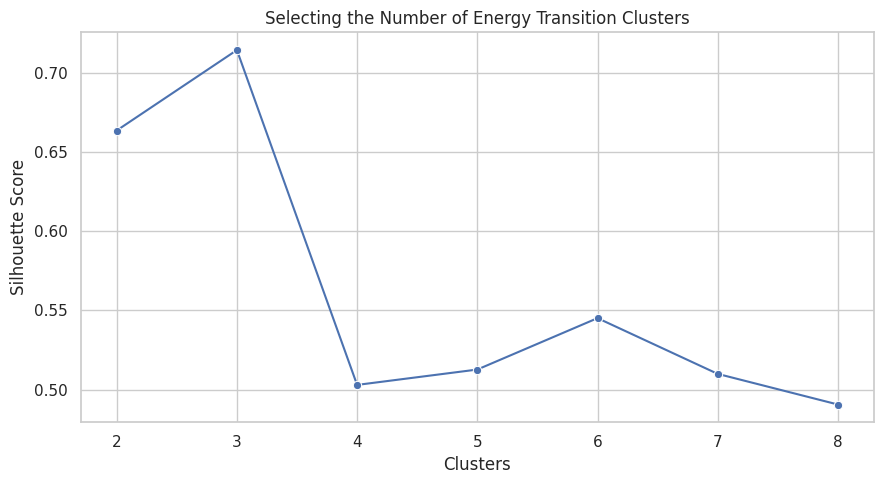

In [63]:
silhouette_results = []

max_k = min(8, len(cluster_table) - 1)

if max_k < 2:
    raise ValueError(
        "Not enough countries for clustering."
    )

for k in range(2, max_k + 1):

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        labels
    )

    silhouette_results.append({
        "Clusters": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=silhouette_df,
    x="Clusters",
    y="Silhouette Score",
    marker="o"
)

plt.title("Selecting the Number of Energy Transition Clusters")
plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "12_cluster_selection.png",
    dpi=300
)

plt.show()

In [64]:
best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "Clusters"
    ]
)

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(
    X_cluster
)

cluster_results = cluster_table.copy()

cluster_results["Cluster"] = cluster_labels

print("K-MEANS MODEL COMPLETED")
print("Number of clusters:", best_k)

display(
    cluster_results.sort_values("Cluster")
)

K-MEANS MODEL COMPLETED
Number of clusters: 3


,renewables_energy_share_pct,fossil_fuels_energy_share_pct,renewable_fossil_share_gap,energy_per_capita_kwh,renewable_growth_pct,gdp_per_capita,Cluster
country,,,,,,,
Kuwait,0.021356,99.978645,-99.957289,107534.539253,99.447738,50659.394777,0
Qatar,0.181194,99.818805,-99.637610,207369.533437,36.372410,135788.209903,0
United Arab Emirates,0.523319,96.613509,-96.090191,129428.877713,56.146333,76839.166812,0
Trinidad and Tobago,0.012005,99.987998,-99.975992,123638.170671,180.910020,27256.041955,0
Oman,0.257997,99.741999,-99.484002,83172.784565,160.451341,37682.205134,0
...,...,...,...,...,...,...,...
Norway,48.702007,51.297995,-2.595988,58024.370432,1.734834,84883.852545,2
South America,22.066216,76.718117,-54.651902,13994.653213,3.773072,NaN,2
Slovenia,9.365833,66.034687,-56.668855,34407.225993,2.037788,29415.578940,2


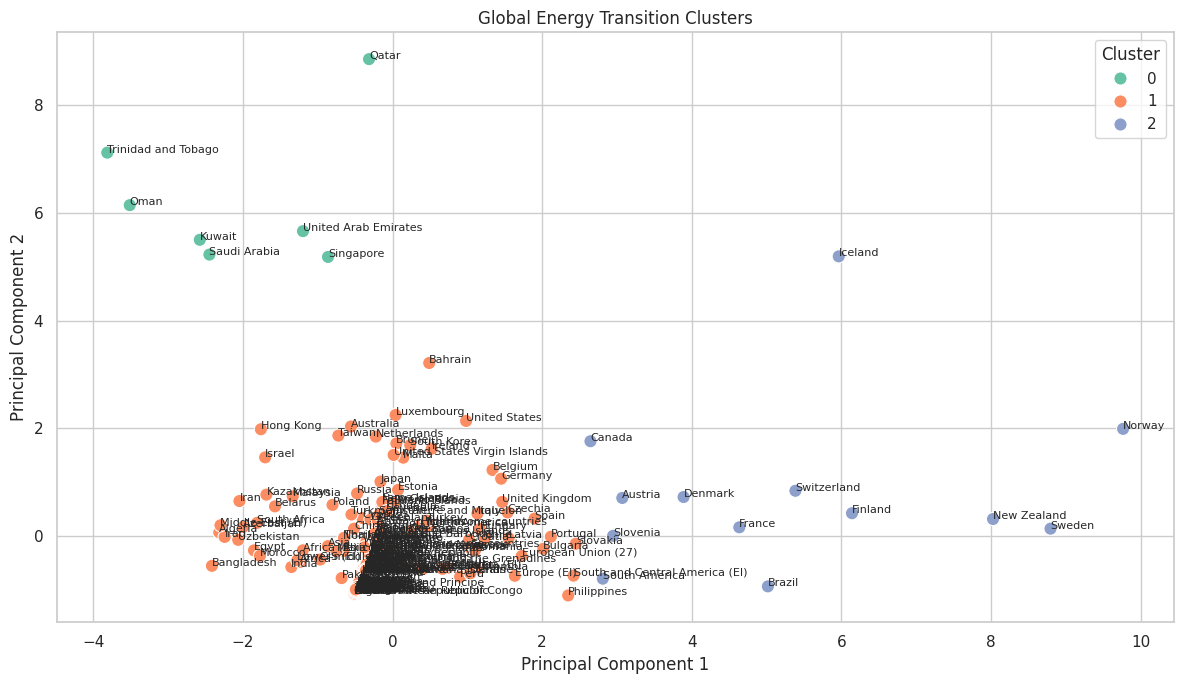

Variance explained by two PCA components: 76.47 %


In [65]:
pca = PCA(n_components=2)

cluster_2d = pca.fit_transform(
    X_cluster
)

pca_results = pd.DataFrame(
    cluster_2d,
    columns=["Principal Component 1", "Principal Component 2"],
    index=cluster_table.index
)

pca_results["Cluster"] = cluster_labels

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=pca_results,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette="Set2",
    s=90
)

for country, row in pca_results.iterrows():
    plt.annotate(
        country,
        (
            row["Principal Component 1"],
            row["Principal Component 2"]
        ),
        fontsize=8
    )

plt.title("Global Energy Transition Clusters")
plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "13_global_energy_clusters.png",
    dpi=300
)

plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [66]:
cluster_interpretation = (
    cluster_results.groupby("Cluster")
    [cluster_table.columns.tolist()]
    .mean()
    .round(3)

)

print("AVERAGE CHARACTERISTICS OF EACH CLUSTER")

display(cluster_interpretation)

AVERAGE CHARACTERISTICS OF EACH CLUSTER


,renewables_energy_share_pct,fossil_fuels_energy_share_pct,renewable_fossil_share_gap,energy_per_capita_kwh,renewable_growth_pct,gdp_per_capita
Cluster,,,,,,
0,0.201,99.389,-99.188,131629.300,90.187,65213.372
1,6.998,88.551,-81.433,19103.574,7.898,14169.332
2,29.078,61.735,-37.366,55613.970,2.550,43896.316


In [67]:
prediction_data = feature_data.copy()

prediction_data = prediction_data.sort_values(
    ["country", "year"]
).reset_index(drop=True)

# Target: next year's renewable energy share
prediction_data["target_next_year"] = (
    prediction_data.groupby("country")[
        "renewables_energy_share_pct"
    ].shift(-1)
)

prediction_data["target_year"] = (
    prediction_data.groupby("country")["year"].shift(-1)
)

# Historical predictors
prediction_features = [
    "renewables_energy_share_pct",
    "fossil_fuels_energy_share_pct"
]

if "renewables_energy_twh" in prediction_data.columns:
    prediction_features.append("renewables_energy_twh")

if "fossil_fuels_energy_twh" in prediction_data.columns:
    prediction_features.append("fossil_fuels_energy_twh")

if "total_energy_twh" in prediction_data.columns:
    prediction_features.append("total_energy_twh")

if "energy_per_capita_kwh" in prediction_data.columns:
    prediction_features.append("energy_per_capita_kwh")

if "gdp_per_capita" in prediction_data.columns:
    prediction_features.append("gdp_per_capita")

# Keep only rows with a valid future target
ml_data = prediction_data.dropna(
    subset=["target_next_year", "target_year"]
).copy()

print("Prediction dataset prepared.")
print("Predictor columns:", prediction_features)
print("Observations:", len(ml_data))

display(ml_data.head())

Prediction dataset prepared.
Predictor columns: ['renewables_energy_share_pct', 'fossil_fuels_energy_share_pct', 'renewables_energy_twh', 'fossil_fuels_energy_twh', 'total_energy_twh', 'energy_per_capita_kwh', 'gdp_per_capita']
Observations: 2450


,country,year,total_energy_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_energy_share_pct,fossil_fuels_energy_share_pct,population,gdp,renewable_fossil_share_gap,renewable_to_fossil_ratio,energy_per_capita_kwh,gdp_per_capita,renewable_growth_pct,fossil_growth_pct,target_next_year,target_year
51,Africa,2000,3051.677734,85.390076,2926.863281,2.798136,95.909973,830226481.0,NaN,-93.111838,0.029175,3675.717174,NaN,NaN,NaN,2.901817,2001.0
52,Africa,2001,3163.087891,91.787018,3038.819092,2.901817,96.071281,851317075.0,NaN,-93.169464,0.030205,3715.522669,NaN,7.491435,3.825112,2.995178,2002.0
53,Africa,2002,3194.898193,95.692894,3062.869141,2.995178,95.867500,873025213.0,NaN,-92.872322,0.031243,3659.571506,NaN,4.255369,0.791427,2.944297,2003.0
54,Africa,2003,3301.009521,97.191513,3165.445557,2.944297,95.893257,895336412.0,NaN,-92.948961,0.030704,3686.892968,NaN,1.566071,3.349030,2.935829,2004.0
55,Africa,2004,3564.072998,104.635086,3418.937500,2.935829,95.927826,918363272.0,NaN,-92.991997,0.030605,3880.896707,NaN,7.658666,8.008097,2.900869,2005.0


In [68]:
X = ml_data[prediction_features]

y = ml_data["target_next_year"]

train_mask = ml_data["target_year"] <= 2019
test_mask = ml_data["target_year"] >= 2020

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("TRAINING OBSERVATIONS:", len(X_train))
print("TESTING OBSERVATIONS:", len(X_test))

print(
    "Training target years:",
    ml_data.loc[train_mask, "target_year"].min(),
    "to",
    ml_data.loc[train_mask, "target_year"].max()
)

print(
    "Testing target years:",
    ml_data.loc[test_mask, "target_year"].min(),
    "to",
    ml_data.loc[test_mask, "target_year"].max()
)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError(
        "Insufficient observations for chronological testing. "
        "Check the dataset's available years."
    )

TRAINING OBSERVATIONS: 1862
TESTING OBSERVATIONS: 588
Training target years: 2001.0 to 2019.0
Testing target years: 2020.0 to 2025.0


In [69]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Machine Learning pipelines created!")

Machine Learning pipelines created!


In [70]:
linear_model.fit(
    X_train,
    y_train
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Linear Regression trained successfully!")
print("Random Forest trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


In [71]:
linear_predictions = linear_model.predict(
    X_test
)

rf_predictions = random_forest_model.predict(
    X_test
)

# Previous-year persistence baseline
baseline_predictions = (
    X_test["renewables_energy_share_pct"]
    .values
)

print("Predictions generated!")

Predictions generated!


In [72]:
def evaluate_model(name, actual, predicted):

    return {
        "Model": name,

        "MAE": mean_absolute_error(
            actual, predicted
        ),

        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),

        "R2 Score": r2_score(
            actual, predicted
        )
    }


model_results = pd.DataFrame([
    evaluate_model(
        "Previous Year Baseline",
        y_test,
        baseline_predictions
    ),

    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    ),

    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
])

display(
    model_results.round(4)
)

,Model,MAE,RMSE,R2 Score
0,Previous Year Baseline,0.7665,1.1603,0.9907
1,Linear Regression,0.7002,1.0859,0.9919
2,Random Forest,0.8405,1.5794,0.9829


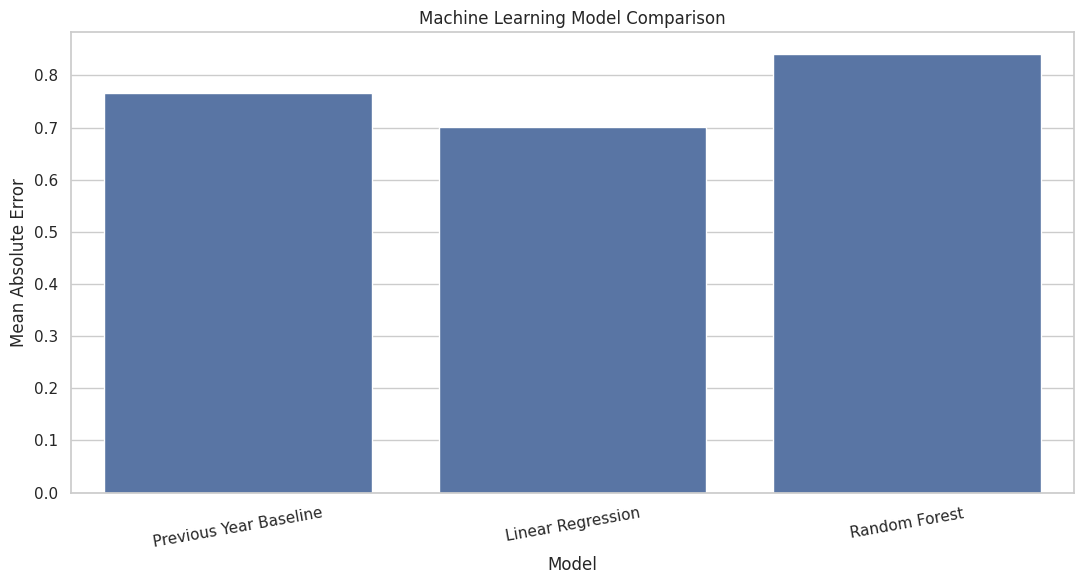

In [73]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=model_results,
    x="Model",
    y="MAE"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=10)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "14_model_comparison.png",
    dpi=300
)

plt.show()

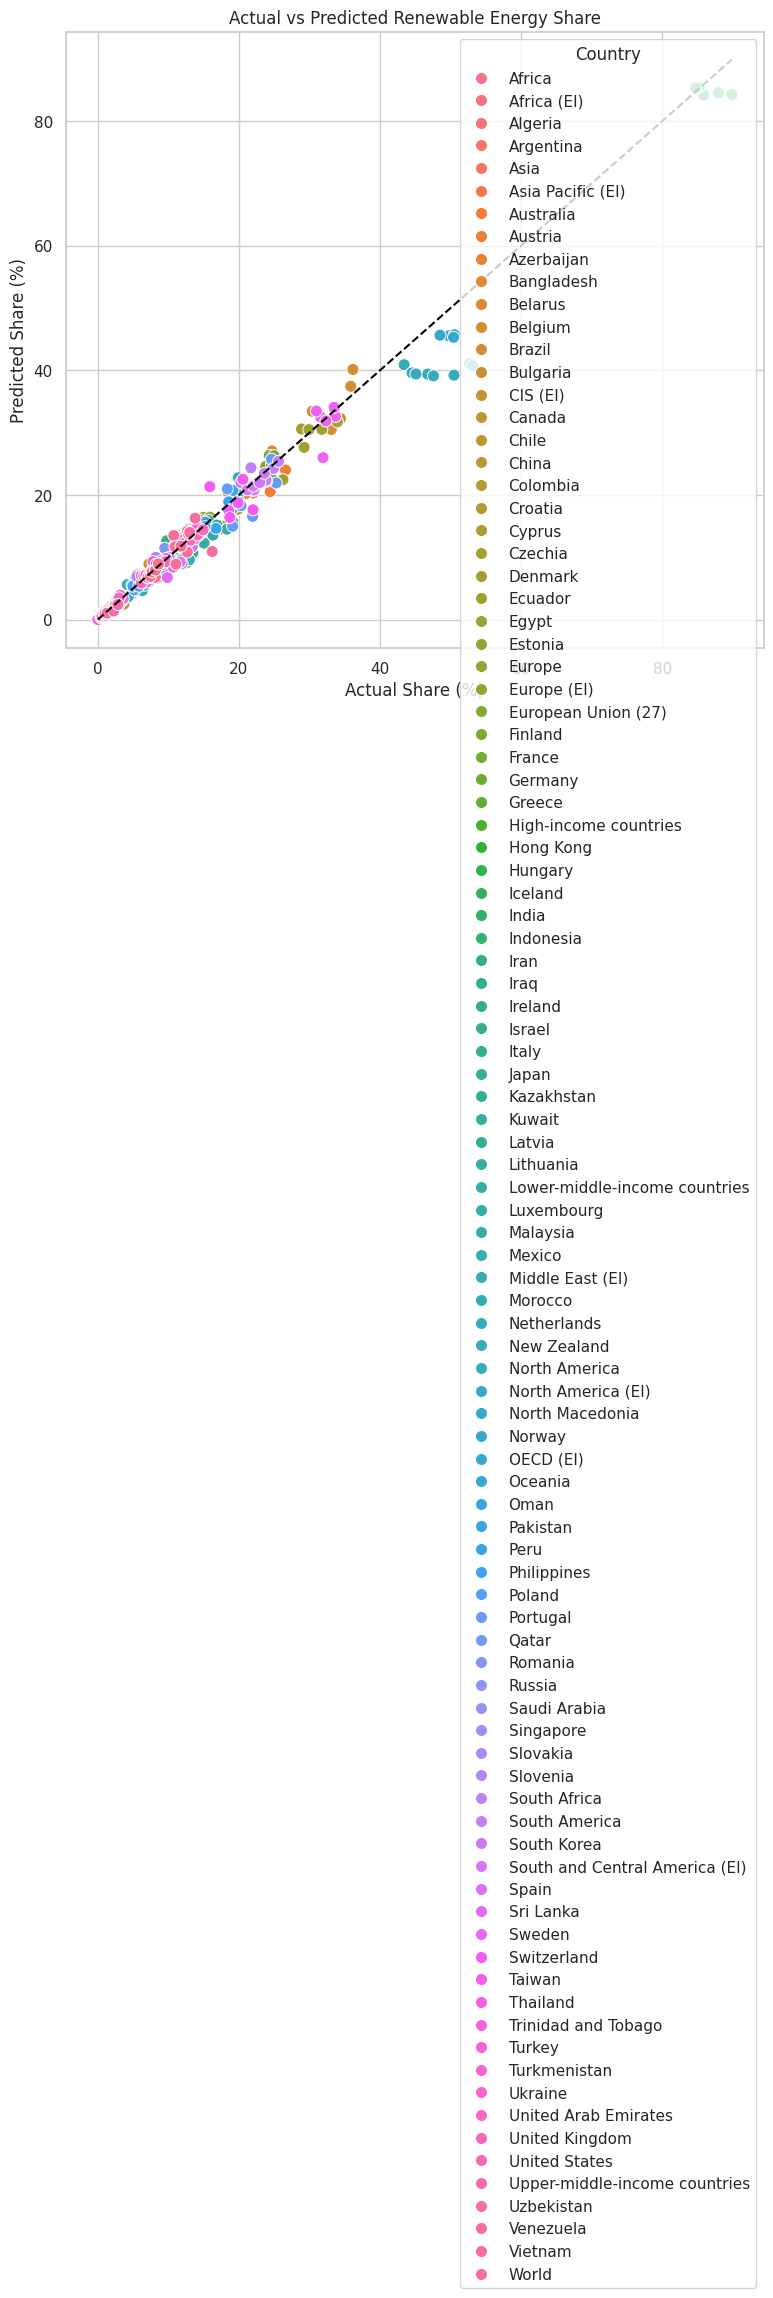

In [74]:
prediction_results = pd.DataFrame({
    "Country": ml_data.loc[test_mask, "country"].values,
    "Target Year": ml_data.loc[test_mask, "target_year"].values,
    "Actual": y_test.values,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions,
    "Previous Year Baseline": baseline_predictions
})

plt.figure(figsize=(9, 8))

sns.scatterplot(
    data=prediction_results,
    x="Actual",
    y="Random Forest",
    hue="Country",
    s=75
)

minimum = min(
    prediction_results["Actual"].min(),
    prediction_results["Random Forest"].min()
)

maximum = max(
    prediction_results["Actual"].max(),
    prediction_results["Random Forest"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="black"
)

plt.title("Actual vs Predicted Renewable Energy Share")
plt.xlabel("Actual Share (%)")
plt.ylabel("Predicted Share (%)")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "15_actual_vs_predicted.png",
    dpi=300
)

plt.show()

In [75]:
country_prediction_summary = pd.DataFrame([
    {
        "Country": country,
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group["Actual"],
            group["Random Forest"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                group["Actual"],
                group["Random Forest"]
            )
        )
    }
    for country, group in prediction_results.groupby("Country")
])

display(country_prediction_summary.round(3))

,Country,Observations,MAE,RMSE
0,Africa,6,0.246,0.263
1,Africa (EI),6,0.200,0.239
2,Algeria,6,0.011,0.015
3,Argentina,6,0.633,0.655
4,Asia,6,0.201,0.252
...,...,...,...,...
93,Upper-middle-income countries,6,0.390,0.461
94,Uzbekistan,6,0.348,0.436
95,Venezuela,6,1.979,2.534
96,Vietnam,6,1.484,1.735


,Feature,Importance
0,renewables_energy_share_pct,0.899984
4,total_energy_twh,0.039859
5,energy_per_capita_kwh,0.039835
1,fossil_fuels_energy_share_pct,0.012067
2,renewables_energy_twh,0.005530
6,gdp_per_capita,0.001524
3,fossil_fuels_energy_twh,0.001201


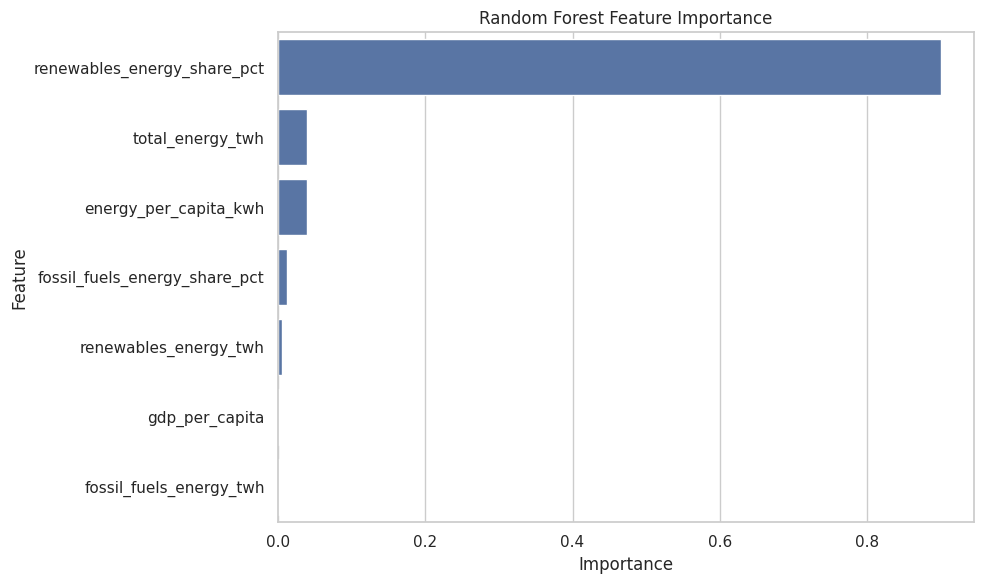

In [76]:
rf_estimator = random_forest_model.named_steps["model"]

importance = pd.DataFrame({
    "Feature": prediction_features,
    "Importance": rf_estimator.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "16_feature_importance.png",
    dpi=300
)

plt.show()

In [77]:
best_model_row = model_results.loc[
    model_results["MAE"].idxmin()
]

print("MODEL PERFORMANCE SUMMARY")
print("--------------------------")

print("Best model:", best_model_row["Model"])
print("MAE:", round(best_model_row["MAE"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("R2 Score:", round(best_model_row["R2 Score"], 4))

if best_model_row["Model"] == "Previous Year Baseline":
    print(
        "\nThe Machine Learning models did not outperform "
        "the previous-year baseline on MAE."
    )
else:
    print(
        "\nThe selected model achieved the lowest MAE "
        "among the evaluated approaches."
    )

MODEL PERFORMANCE SUMMARY
--------------------------
Best model: Linear Regression
MAE: 0.7002
RMSE: 1.0859
R2 Score: 0.9919

The selected model achieved the lowest MAE among the evaluated approaches.


In [78]:
print("=" * 55)
print("GREEN MIRAGE 2.0 - RESEARCH OBSERVATIONS")
print("=" * 55)

print("\n1. RENEWABLE ENERGY")

highest_renewable = research_summary.loc[
    research_summary["average_renewable_share"].idxmax()
]

print(
    f"{highest_renewable['country']} has the highest "
    "average renewable energy share among the five "
    "selected countries over the available study period."
)

print("\n2. FOSSIL-FUEL DEPENDENCE")

highest_fossil = research_summary.loc[
    research_summary["average_fossil_share"].idxmax()
]

print(
    f"{highest_fossil['country']} has the highest "
    "average fossil-fuel energy share among the five "
    "selected countries."
)

print("\n3. MACHINE LEARNING")

print(
    "The best-performing evaluated approach is:",
    best_model_row["Model"]
)

print("\n4. CLUSTERING")

print(
    "The clustering experiment identified",
    best_k,
    "groups of countries with similar selected energy indicators."
)

print("\n5. IMPORTANT LIMITATION")

print(
    "Renewable energy growth does not automatically "
    "establish fossil-fuel displacement."
)

GREEN MIRAGE 2.0 - RESEARCH OBSERVATIONS

1. RENEWABLE ENERGY
Brazil has the highest average renewable energy share among the five selected countries over the available study period.

2. FOSSIL-FUEL DEPENDENCE
India has the highest average fossil-fuel energy share among the five selected countries.

3. MACHINE LEARNING
The best-performing evaluated approach is: Linear Regression

4. CLUSTERING
The clustering experiment identified 3 groups of countries with similar selected energy indicators.

5. IMPORTANT LIMITATION
Renewable energy growth does not automatically establish fossil-fuel displacement.


In [79]:
conclusion = f"""
GREEN MIRAGE 2.0
GLOBAL ENERGY TRANSITION INTELLIGENCE SYSTEM

PROJECT CONCLUSION
==================

Green Mirage 2.0 investigated renewable energy growth
and fossil-fuel dependence using data from Our World
in Data.

The detailed country analysis focused on:

India, China, Germany, Brazil and the United States.

The project applied data cleaning, exploratory analysis,
feature engineering, visualization and Machine Learning.

RESEARCH FINDINGS
-----------------

The five-country comparison identified:

Highest average renewable share:
{highest_renewable['country']}

Highest average fossil-fuel share:
{highest_fossil['country']}

MACHINE LEARNING
----------------

Clustering groups identified:
{best_k}

Best-performing evaluated approach:
{best_model_row['Model']}

MAE:
{best_model_row['MAE']:.4f}

RMSE:
{best_model_row['RMSE']:.4f}

R2:
{best_model_row['R2 Score']:.4f}

RESEARCH LIMITATIONS
--------------------

1. Historical data availability differs across countries.
2. The analysis does not establish causal relationships.
3. Country clustering depends on selected features.
4. Prediction performance depends on the available
   observations and the chronological test period.
5. Model performance must be compared with simple
   baseline approaches.

OVERALL CONCLUSION
------------------

The project demonstrates how Data Science and Machine
Learning can be applied to investigate energy transition
patterns and evaluate historical relationships between
renewable and fossil-fuel energy indicators.

The results should be interpreted as exploratory
evidence rather than definitive forecasts of future
national energy policies.

Dataset:
Our World in Data - Global Energy Dataset.
"""

print(conclusion)


GREEN MIRAGE 2.0
GLOBAL ENERGY TRANSITION INTELLIGENCE SYSTEM

PROJECT CONCLUSION

Green Mirage 2.0 investigated renewable energy growth
and fossil-fuel dependence using data from Our World
in Data.

The detailed country analysis focused on:

India, China, Germany, Brazil and the United States.

The project applied data cleaning, exploratory analysis,
feature engineering, visualization and Machine Learning.

RESEARCH FINDINGS
-----------------

The five-country comparison identified:

Highest average renewable share:
Brazil

Highest average fossil-fuel share:
India

MACHINE LEARNING
----------------

Clustering groups identified:
3

Best-performing evaluated approach:
Linear Regression

MAE:
0.7002

RMSE:
1.0859

R2:
0.9919

RESEARCH LIMITATIONS
--------------------

1. Historical data availability differs across countries.
2. The analysis does not establish causal relationships.
3. Country clustering depends on selected features.
4. Prediction performance depends on the available
   

In [80]:
research_summary.to_csv(
    OUTPUT_DIR / "five_country_research_summary.csv",
    index=False
)

cluster_results.to_csv(
    OUTPUT_DIR / "global_country_clusters.csv"
)

cluster_interpretation.to_csv(
    OUTPUT_DIR / "cluster_interpretation.csv"
)

model_results.to_csv(
    OUTPUT_DIR / "model_performance.csv",
    index=False
)

prediction_results.to_csv(
    OUTPUT_DIR / "renewable_energy_predictions.csv",
    index=False
)

country_prediction_summary.to_csv(
    OUTPUT_DIR / "country_prediction_summary.csv",
    index=False
)

importance.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

missing_report.to_csv(
    OUTPUT_DIR / "missing_value_report.csv",
    index=False
)

print("Research tables exported successfully!")

Research tables exported successfully!


In [81]:
with open(
    OUTPUT_DIR / "project_conclusion.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(conclusion)

print("Research conclusion saved!")

Research conclusion saved!


In [82]:
source_information = f"""
PROJECT: GREEN MIRAGE 2.0

DATASET:
Our World in Data - Global Energy Dataset

SOURCE:
{DATA_URL}

COUNTRIES:
{", ".join(COUNTRIES)}

STUDY PERIOD:
{START_YEAR} to {END_YEAR}

NOTE:
Only observations available in the original dataset
are included. Missing values are not automatically
treated as zero.

The original dataset is retrieved directly from OWID.
"""

with open(
    OUTPUT_DIR / "dataset_source.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(source_information)

print("Dataset source information saved!")

Dataset source information saved!


In [83]:
print("=" * 55)
print("GREEN MIRAGE 2.0 - FINAL PROJECT AUDIT")
print("=" * 55)

checks = {
    "Dataset loaded": len(df) > 0,

    "Five-country analysis created": (
        case_study["country"].nunique() > 0
    ),

    "Feature engineering completed": (
        "renewable_fossil_share_gap" in feature_data.columns
    ),

    "Country clustering completed": (
        "Cluster" in cluster_results.columns
    ),

    "Machine Learning models trained": (
        len(model_results) == 3
    ),

    "Predictions generated": (
        len(prediction_results) > 0
    ),

    "Research conclusion generated": (
        len(conclusion) > 0
    ),

    "Research tables exported": (
        len(list(OUTPUT_DIR.glob("*.csv"))) >= 5
    ),

    "Visualizations saved": (
        len(list(VISUALS_DIR.glob("*.png"))) >= 10
    )
}

for name, status in checks.items():

    print(
        ("PASS" if status else "CHECK"),
        "-",
        name
    )

print("\nCompleted checks:", sum(checks.values()), "/", len(checks))

print("\nVisualizations:", len(list(VISUALS_DIR.glob("*.png"))))
print("Result files:", len(list(OUTPUT_DIR.iterdir())))

GREEN MIRAGE 2.0 - FINAL PROJECT AUDIT
PASS - Dataset loaded
PASS - Five-country analysis created
PASS - Feature engineering completed
PASS - Country clustering completed
PASS - Machine Learning models trained
PASS - Predictions generated
PASS - Research conclusion generated
PASS - Research tables exported
PASS - Visualizations saved

Completed checks: 9 / 9

Visualizations: 11
Result files: 10


In [84]:
import shutil
from google.colab import files

# Create ZIP archive of visualizations
shutil.make_archive(
    "Green_Mirage_2_Visualizations",
    "zip",
    VISUALS_DIR
)

# Create ZIP archive of research results
shutil.make_archive(
    "Green_Mirage_2_Research_Results",
    "zip",
    OUTPUT_DIR
)

print("Both project archives are ready!")

# Download both ZIP files
files.download("Green_Mirage_2_Visualizations.zip")
files.download("Green_Mirage_2_Research_Results.zip")

Both project archives are ready!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>